# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


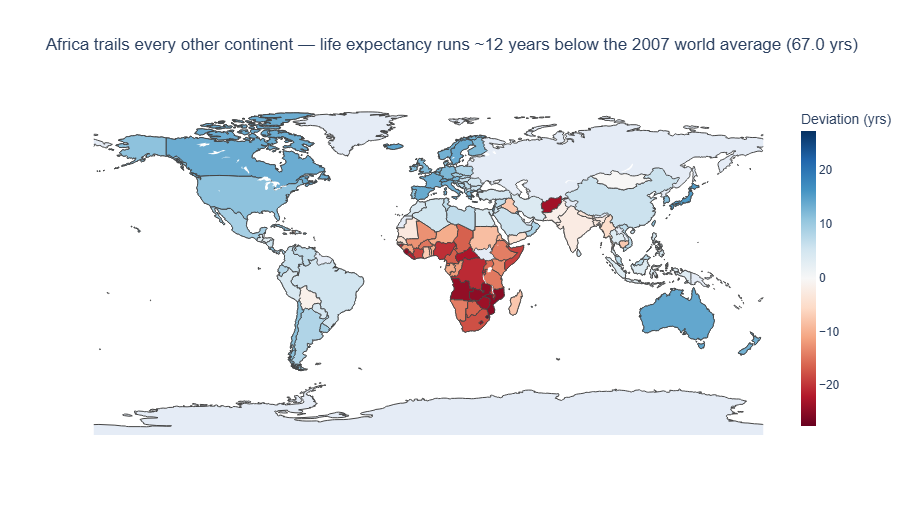

continent
Africa     -12.201384
Asia         3.721062
Americas     6.600697
Europe      10.641177
Oceania     13.712077
Name: deviation, dtype: float64


In [2]:
# Task 1
# YOUR CODE HERE

gm = px.data.gapminder()
gm_2007 = gm.loc[gm['year'] == 2007].copy()

world_avg_lifeExp = gm_2007['lifeExp'].mean()
gm_2007['deviation'] = gm_2007['lifeExp'] - world_avg_lifeExp

fig = px.choropleth(
    gm_2007,
    locations='iso_alpha',
    locationmode='ISO-3',
    color='deviation',
    color_continuous_scale='RdBu',
    color_continuous_midpoint=0,
    hover_name='country',
    hover_data={'lifeExp': ':.1f', 'deviation': ':.1f', 'iso_alpha': False},
    labels={'deviation': f'Deviation from world avg ({world_avg_lifeExp:.1f} yrs)'},
    title=f'Africa trails every other continent — life expectancy runs ~12 years below the 2007 world average ({world_avg_lifeExp:.1f} yrs)',
    height=500,
    width=1000,
)
fig.update_layout(
    font=dict(family='Arial', size=12),
    geo=dict(showframe=False),
    coloraxis_colorbar=dict(title='Deviation (yrs)', thickness=15, len=1),
)
fig.show()

print(gm_2007.groupby('continent')['deviation'].mean().sort_values())


## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** *[Subhash9325/GeoJson-Data-of-Indian-States](https://github.com/Subhash9325/GeoJson-Data-of-Indian-States) on GitHub (file `Indian_States`)*

**Chart type chosen** `px.choropleth` **and reason:** because this is a single static map meant to be read at a glance and there's no need for the pan/zoom/tile basemap that `px.choropleth_map` is built for, and `fitbounds='locations'` is the simplest way to auto-zoom to India.

**Colour scale chosen** sequential **and reason:** because literacy rate is a one-directional measure — there's no meaningful "zero" or natural midpoint to diverge around, just a range from lower to higher literacy. A diverging scale would wrongly imply some states are "below/above" a reference point rather than simply "lower/higher".


{'NAME_1': 'Andaman and Nicobar'}


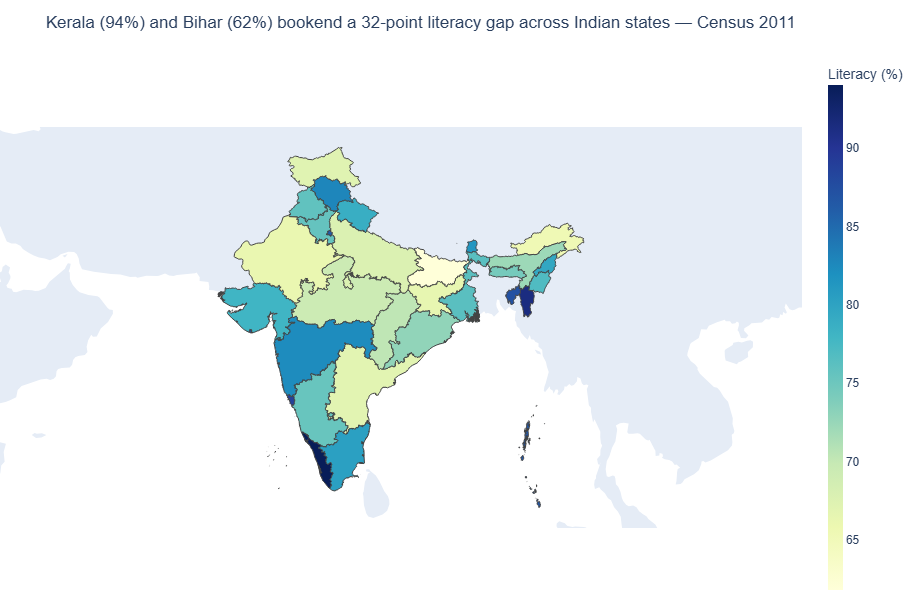

In [3]:
# Task 2
# YOUR CODE HERE

# Load your GeoJSON
# with open('your_file.geojson', 'r') as file:
#     my_geojson = json.load(file)

# Inspect the properties to find the right featureidkey
# print(my_geojson['features'][0]['properties'])


literacy = pd.DataFrame({
    'State': [
        'Andaman and Nicobar', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar',
        'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman and Diu', 'Delhi',
        'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand',
        'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur',
        'Meghalaya', 'Mizoram', 'Nagaland', 'Orissa', 'Puducherry', 'Punjab', 'Rajasthan',
        'Sikkim', 'Tamil Nadu', 'Tripura', 'Uttar Pradesh', 'Uttaranchal', 'West Bengal'
    ],
    'Literacy_Rate': [
        86.63, 67.02, 65.38, 72.19, 61.80,
        86.05, 70.28, 76.24, 87.10, 86.21,
        88.70, 78.03, 75.55, 82.80, 67.16, 66.41,
        75.36, 94.00, 91.85, 69.32, 82.34, 76.94,
        74.43, 91.33, 79.55, 72.87, 85.85, 75.84, 66.11,
        81.42, 80.33, 87.22, 67.68, 78.82, 76.26
    ]
})

with open('india_states.geojson', 'r') as file:
    india_geojson = json.load(file)

print(india_geojson['features'][0]['properties'])

fig = px.choropleth(
    literacy,
    geojson=india_geojson,
    locations='State',
    featureidkey='properties.NAME_1',
    color='Literacy_Rate',
    color_continuous_scale='YlGnBu',
    fitbounds='locations',
    hover_name='State',
    hover_data={'State': False, 'Literacy_Rate': ':.1f'},
    labels={'Literacy_Rate': 'Literacy Rate (%)'},
    title='Kerala (94%) and Bihar (62%) bookend a 32-point literacy gap across Indian states — Census 2011',
    height=600,
    width=800,
)
fig.update_layout(
    font=dict(family='Arial', size=12),
    geo=dict(showframe=False, showcoastlines=False),
    margin=dict(l=0, r=0, t=55, b=0),
    coloraxis_colorbar=dict(title='Literacy (%)', thickness=15, len=1),
)
fig.show()
